# ARTIFICIAL NEURAL NETWORK (ANN)

## Project - Handwritten Digits Classification

In [2]:
pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 1.0/351.2 MB 6.1 MB/s eta 0:00:57
   ---------------------------------------- 2.4/351.2 MB 6.3 MB/s eta 0:00:56
   ---------------------------------------- 3.7/351.2 MB 6.3 MB/s eta 0:00:56
    --------------------------------------- 5.2/351.2 MB 6.3 MB/s eta 0:00:55
    --------------------------------------- 6.6/351.2 MB 6.3 MB/s eta 0:00:55
    --------------------------------------- 7.6/351.2 MB 6.2 MB/s eta 0:00:56
    --------------------------------------- 8.7/351.2 MB 6.1 MB/s eta 0:00:56
   - -------------------------------------- 9.7/351.2 MB 5.9 MB/s eta 0:00:58
   - -------------------------------------- 10.2/351.2 MB 5.7 MB/s eta 0:01:00
   - -------------------------------------- 10.7/351.2 MB 5.4 MB/s eta 0:01:04
   - -------------------------------------- 11.5/351.2 MB 5.0 MB/s eta 0:01:08
   - -------------------------------------- 12.1/351.2 MB 4.9 MB/s e

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.35.1 which is incompatible.


In [3]:
# Import necessary libraries:

import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

In [4]:
# Read 'mnist.csv' dataset and store it in a DataFrame variable

data = pd.read_csv('Downloads/mnist.csv')

In [5]:
# View the data

data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
# View the column names

data.columns

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=785)

In [7]:
# Check the shape of the data
# Means that we have 42000 rows(images) and 785 columns

data.shape

(42000, 785)

In [8]:
# Split the data set into X and y variables (Input and target)
# Note that 'label' column in the dataset is our target

X = data.drop(columns = ['label'])
y = data['label']

In [9]:
# Check the shape of X and y

X.shape

(42000, 784)

In [10]:
y.shape

(42000,)

In [11]:
# Reshape X to (len(X),28,28,1)

X = X.values.reshape((len(X),28,28,1))

In [12]:
# Check the shape of X

X.shape

(42000, 28, 28, 1)

In [13]:
#  Normalise the data by dividing it by 255

X = X/255

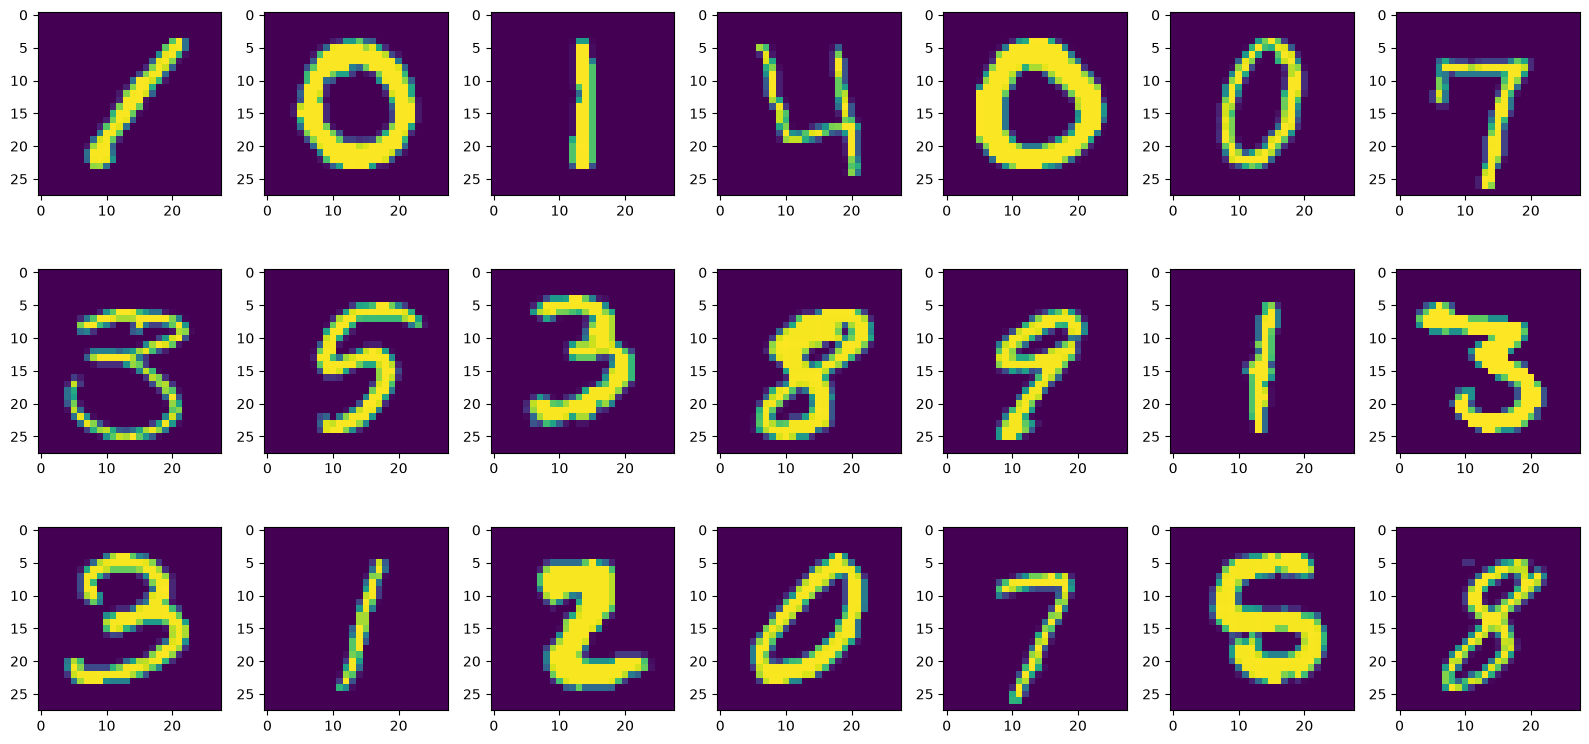

In [14]:
# Plot the first few digits

plt.figure(figsize = (16,8))
for i in range(21):
    plt.subplot(3,7,i+1)
    plt.imshow(X[i])
plt.tight_layout()

In [15]:
# Split the dataset into Training and Testing set

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2)

In [16]:
# Check the shape of X_train and X_test

X_train.shape

(33600, 28, 28, 1)

In [17]:
X_test.shape

(8400, 28, 28, 1)

In [18]:
# Create a Keras Sequential model

model = keras.Sequential([
                  keras.layers.Flatten(input_shape = (28,28)),
                  keras.layers.Dense(100, activation="relu"),
                  keras.layers.Dense(10,activation="sigmoid")
])

C:\Users\varsh\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [19]:
# Compile Keras Model

model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy',metrics = ['accuracy'])

In [20]:
# Check the summary of our model

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Fit Keras Model

model.fit(X_train,y_train, epochs = 5, validation_split=0.05, batch_size = 20)

Epoch 1/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9065 - loss: 0.3228 - val_accuracy: 0.9458 - val_loss: 0.1949
Epoch 2/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9569 - loss: 0.1481 - val_accuracy: 0.9548 - val_loss: 0.1536
Epoch 3/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9694 - loss: 0.1018 - val_accuracy: 0.9619 - val_loss: 0.1165
Epoch 4/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9770 - loss: 0.0769 - val_accuracy: 0.9667 - val_loss: 0.1075
Epoch 5/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9836 - loss: 0.0583 - val_accuracy: 0.9702 - val_loss: 0.0955


In [22]:
# Evaluate Keras Model

model.evaluate(X_train, y_train)

1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9887 - loss: 0.0402


[0.04024006053805351, 0.9886904954910278]

In [23]:
# Make predicitons using X_test and store it in a variable

prediction = model.predict(X_test)

263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [24]:
# View prediciton

prediction

array([[3.1321219e-03, 2.5196290e-02, 1.6381913e-01, ..., 9.9992210e-01,
        2.6005956e-03, 5.3182598e-02],
       [9.7871321e-01, 1.1298951e-07, 2.9583104e-04, ..., 9.9999928e-01,
        1.5597626e-04, 9.9896091e-01],
       [2.6441053e-03, 3.1849503e-04, 4.6276391e-01, ..., 9.9998355e-01,
        3.0486941e-02, 7.9892993e-02],
       ...,
       [4.1695256e-02, 1.4420925e-04, 8.2842875e-01, ..., 8.6379901e-02,
        2.5371320e-03, 9.3297017e-01],
       [1.4246245e-02, 1.5596235e-01, 9.9997652e-01, ..., 1.8176075e-02,
        6.9800988e-02, 5.7718164e-04],
       [2.2892107e-01, 6.7589790e-02, 9.6064508e-01, ..., 8.4542021e-02,
        6.8045473e-01, 4.2525022e-03]], shape=(8400, 10), dtype=float32)

In [25]:
# Check the first predicted value and plot the corresponding data

np.argmax(prediction[0])

np.int64(7)

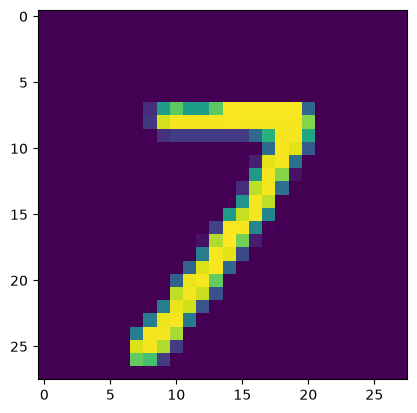

In [26]:
 plt.imshow(X_test[0])

In [27]:
# Store all the predicted values as numbers in a list
# Use list comprehension to achieve this task

predicted_values = [np.argmax(i) for i in prediction]

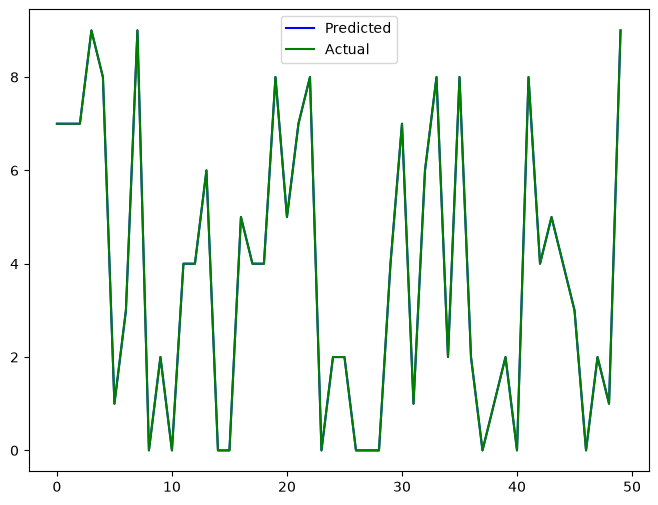

In [28]:
# Plot the accuracy of our prediction

c = range(len(predicted_values))
plt.figure(figsize = (8,6))
plt.plot(c[:50], predicted_values[:50], color = 'blue')
plt.plot(c[:50], y_test[:50], color = 'green')
plt.legend(['Predicted', 'Actual'])
plt.show()

Text(70.83333333333333, 0.5, 'Actual Values')

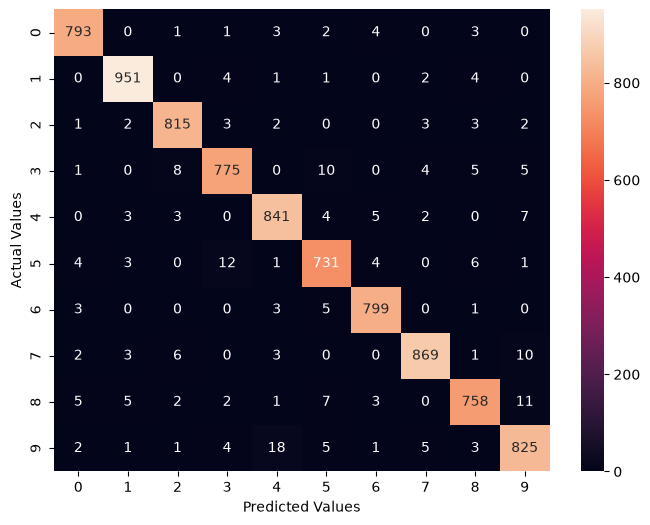

In [29]:
# Plot confusion matrix using heatmap

plt.figure(figsize = (8,6))
sns.heatmap(confusion_matrix(y_test,predicted_values), annot = True, fmt = 'd')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

# CONVOLUTIONAL NEURAL NETWORK (CNN)

## Project - Cats & Dogs Classification

In [1]:
# Import necessary libraries

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.utils import shuffle
from skimage.transform import resize
from sklearn.metrics import confusion_matrix
import glob

In [2]:
# Fetch the Training data

cats = glob.glob("Downloads/Cats & Dogs Classification Files/Cats & Dogs Classification Files/cat and dog/training_set/cats/*.jpg")
dogs = glob.glob("Downloads/Cats & Dogs Classification Files/Cats & Dogs Classification Files/cat and dog/training_set/dogs/*.jpg")

In [4]:
# Fetch the testing data

cats_test = glob.glob('Downloads/Cats & Dogs Classification Files/Cats & Dogs Classification Files/cat and dog/test_set/cats/*.jpg')
dogs_test = glob.glob('Downloads/Cats & Dogs Classification Files/Cats & Dogs Classification Files/cat and dog/test_set/dogs/*.jpg')

In [5]:
# Check the Number of images of Cats and Dogs in Training ,Testing Set

print("Number of images in Training are, Cats:",len(cats),",Dogs:",len(dogs))
print("Number of images in Testing are, Cats:",len(cats_test),",Dogs:",len(dogs_test))

Number of images in Training are, Cats: 108 ,Dogs: 107
Number of images in Testing are, Cats: 38 ,Dogs: 56


In [6]:
# Check the datatype of Training and Testing Set(Both Cat and Dog)

print("Datatype of Training set, Cats:", type(cats),",Dogs:",type(dogs))
print("Datatype of Testing set, Cats:", type(cats_test),",Dogs:",type(dogs_test))

Datatype of Training set, Cats: <class 'list'> ,Dogs: <class 'list'>
Datatype of Testing set, Cats: <class 'list'> ,Dogs: <class 'list'>


In [7]:
# Create a list with the images and a seperate one with its corresponding labels for both training and testing set
# Training set

image = []
label = []

for i in cats:
    img = plt.imread(i)
    image.append(img)
    label.append(0)

    
for i in dogs:
    img = plt.imread(i)
    image.append(img)
    label.append(1)

In [8]:
# Testing set

image_test = []
label_test = []


for i in cats_test:
    img = plt.imread(i)
    image_test.append(img)
    label_test.append(0)

for i in dogs_test:
    img = plt.imread(i)
    image_test.append(img)
    label_test.append(1)

In [9]:
# Shuffle both images and labels
# Training set

image, label = shuffle(image,label, random_state = 100)

In [10]:
# Testing set

image_test, label_test = shuffle(image_test,label_test, random_state = 100)

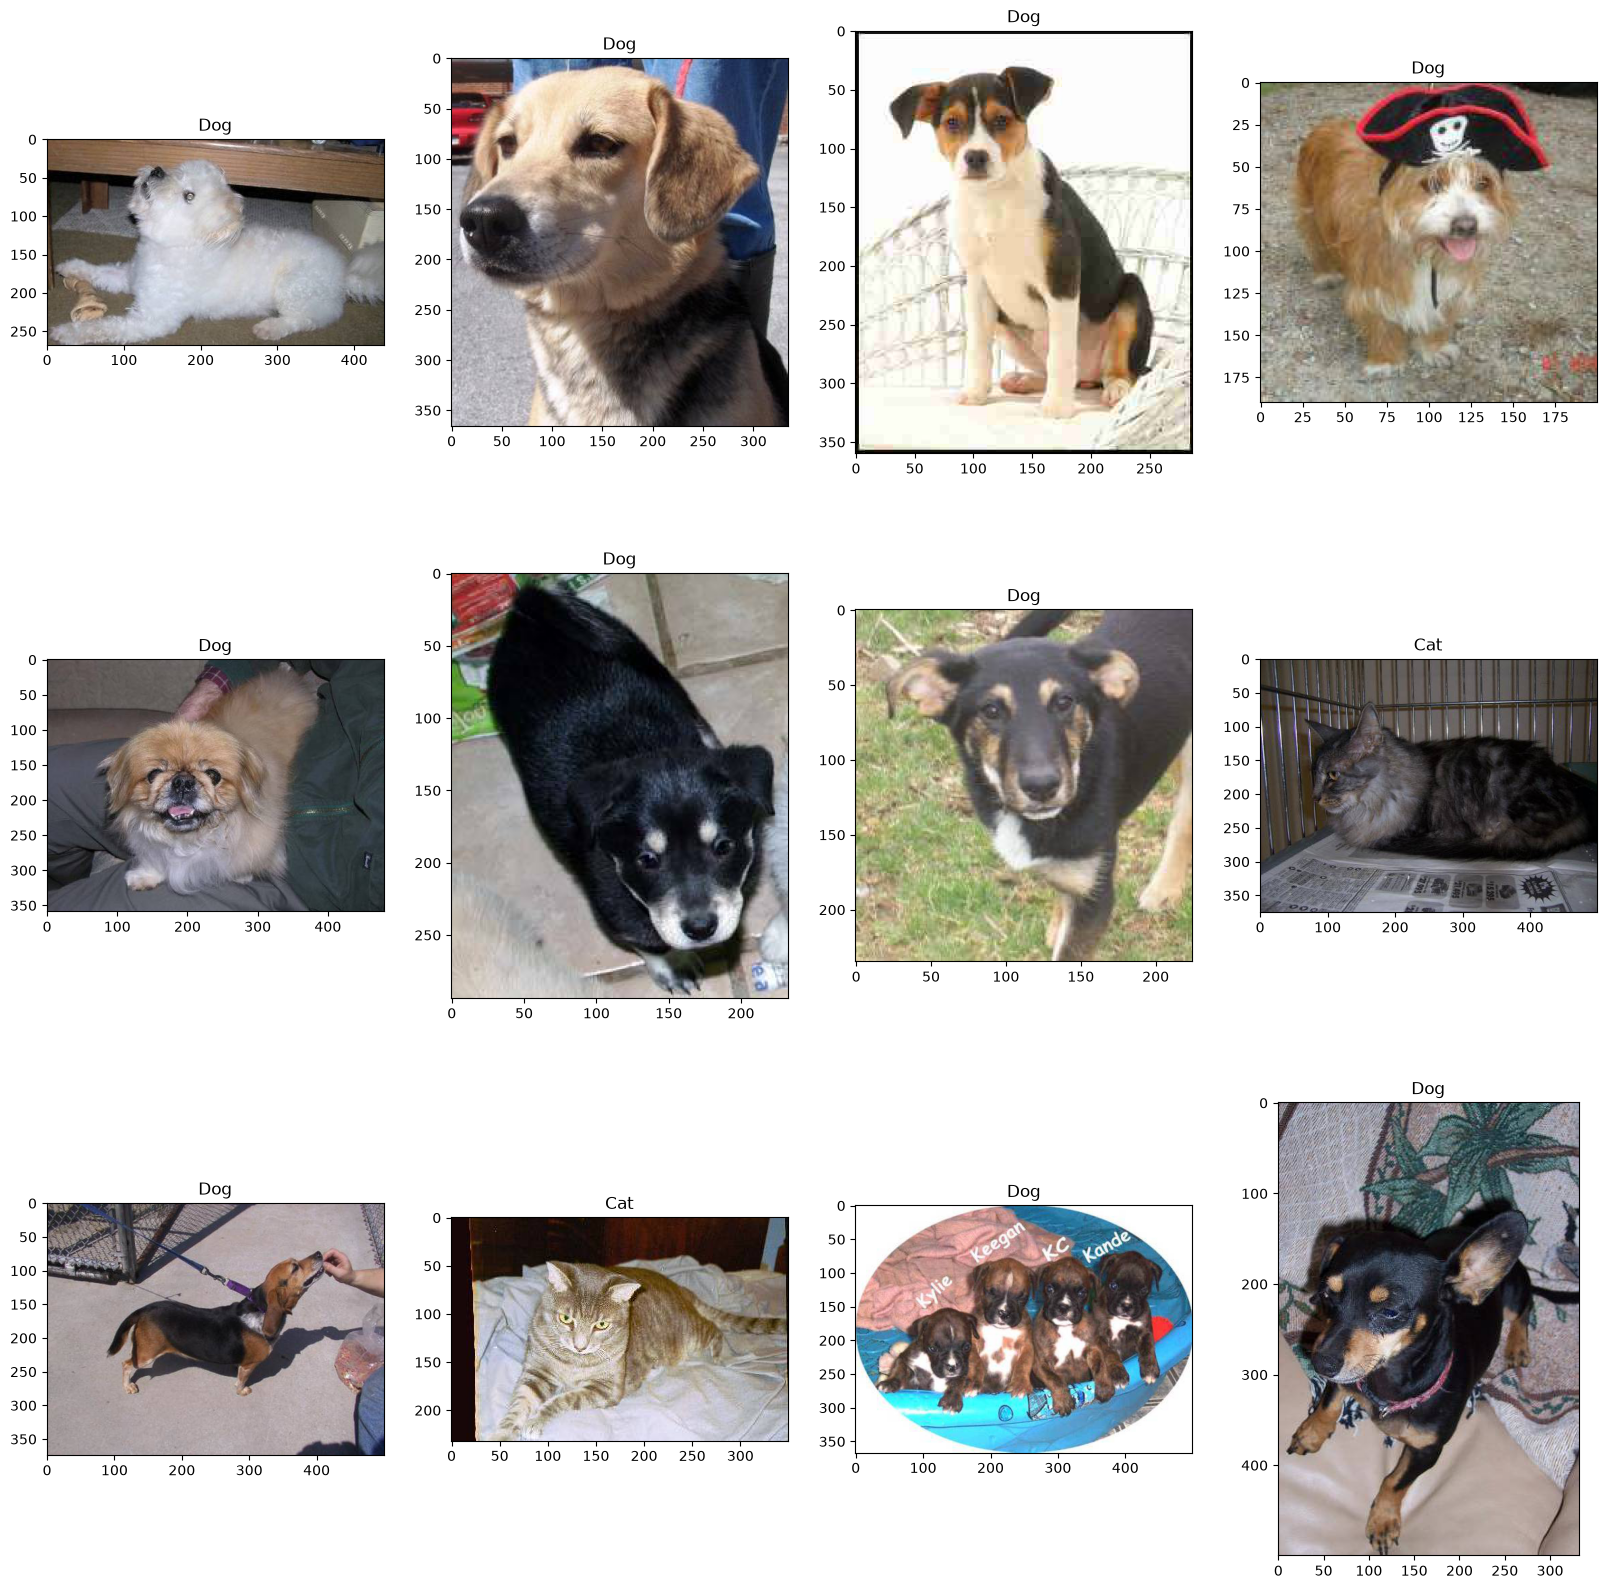

In [11]:
# Plot a few images of Both Categories

plt.figure(figsize = (20,20))
for i in range(12):
    plt.subplot(3,4,i+1)
    plt.imshow(image[i])
    if label[i] == 1:
        plt.title('Dog')
    else:
        plt.title('Cat')

In [17]:
# Resize the images to 64X64
# Training set

X_train = []

for i in image:
    X_train.append(resize(i,(64,64,3)))
    
X_train = np.array(X_train)

In [18]:
# Testing set

X_test = []

for i in image_test:
    X_test.append(resize(i,(64,64,3)))
    
X_test = np.array(X_test)

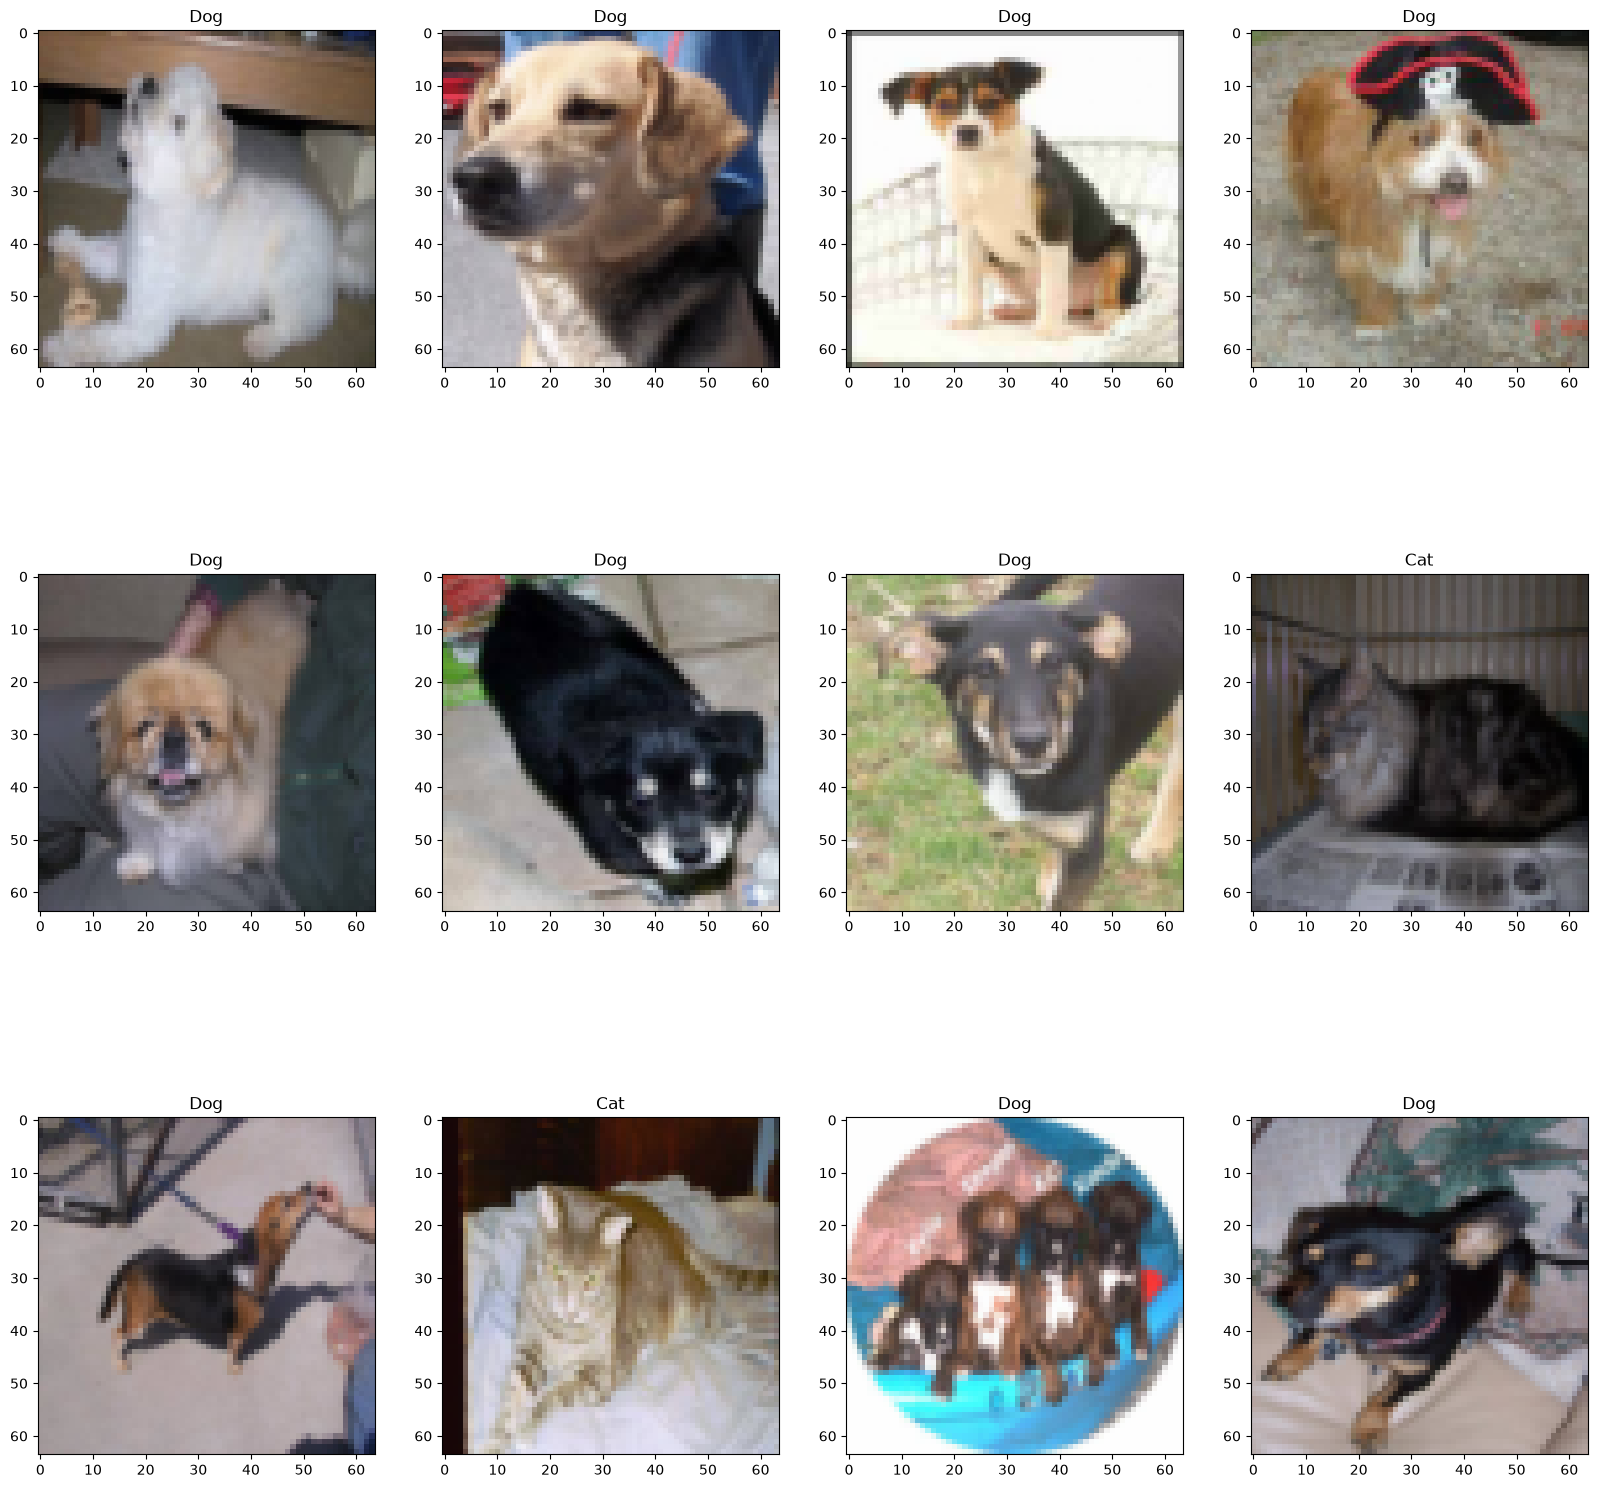

In [31]:
# Plot some of the resized images

plt.figure(figsize = (20,20))
for i in range(12):
    plt.subplot(3,4,i+1)
    plt.imshow(X_train[i])
    if label[i] == 1:
        plt.title('Dog')
    else:
        plt.title('Cat')

In [32]:
# Check the datatype of X_train and Label

print(type(X_train))
print(type(label))

<class 'numpy.ndarray'>
<class 'list'>


In [33]:
# Convert label and test_label to Numpy array and store it in y_train and y_test

y_train = np.array(label)
y_test = np.array(label_test)

In [34]:
print(type(y_train))
print(type(y_test))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [35]:
# Check the shape of X_train and y_train

X_train.shape

(215, 64, 64, 3)

In [36]:
y_train.shape

(215,)

In [37]:
# Create Keras Sequential model with 2 convolution layer, Flatten and a Hidden layer

model = keras.models.Sequential([
    keras.layers.Conv2D(16, (3,3), activation = 'relu', input_shape = (64, 64, 3)),
    keras.layers.MaxPool2D(2,2),
    
    keras.layers.Conv2D(32,(3,3), activation = 'relu'),
    keras.layers.MaxPool2D(2,2),
    
    keras.layers.Flatten(),
    
    keras.layers.Dense(64, activation = 'relu'),
    keras.layers.Dense(1, activation = 'sigmoid')
])

C:\Users\varsh\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [38]:
# Compile our model

model.compile(optimizer = 'adam',
             loss = 'binary_crossentropy',
             metrics = ['accuracy'])

In [39]:
# Check model summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 16)          │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 6272)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         401,472 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 406,625 (1.55 MB)

 Trainable params: 406,625 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# Train our model with X_train and y_train

model.fit(X_train,y_train, epochs=30, steps_per_epoch=3, validation_split=0.1)

Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 425ms/step - accuracy: 0.5285 - loss: 0.8202 - val_accuracy: 0.6818 - val_loss: 0.6883
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.4819 - loss: 0.8574 - val_accuracy: 0.6818 - val_loss: 0.6567
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.5285 - loss: 0.6929 - val_accuracy: 0.3182 - val_loss: 0.7854
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.5181 - loss: 0.6960 - val_accuracy: 0.3182 - val_loss: 0.7802
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.5181 - loss: 0.6885 - val_accuracy: 0.3182 - val_loss: 0.7344
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.5181 - loss: 0.6797 - val_accuracy: 0.3182 - val_loss: 0.7089
Epoch 7/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.6062 - loss: 0.6775 - val_accuracy: 0.4545 - val_loss: 0.7005
Epoch 8/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.6218 - loss: 0.6713 - val_accuracy: 0.3182 - val_loss:

In [41]:
# Evaluate our model

model.evaluate(X_train, y_train)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9302 - loss: 0.2641


[0.264095276594162, 0.930232584476471]

In [42]:
# Make predictions with X_test

prediction = model.predict(X_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step


In [43]:
prediction[:5]

array([[0.762262  ],
       [0.9308226 ],
       [0.22543105],
       [0.38771078],
       [0.5011135 ]], dtype=float32)

In [44]:
# Our prediction is numbers ranging from 0 to 1. We can convert values less than 0.5 to 0 and rest to 1.

pred = []

for i in prediction:
    if i > 0.5:
        pred.append(0)
    else:
        pred.append(1)

In [48]:
print(pred)

[0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1]


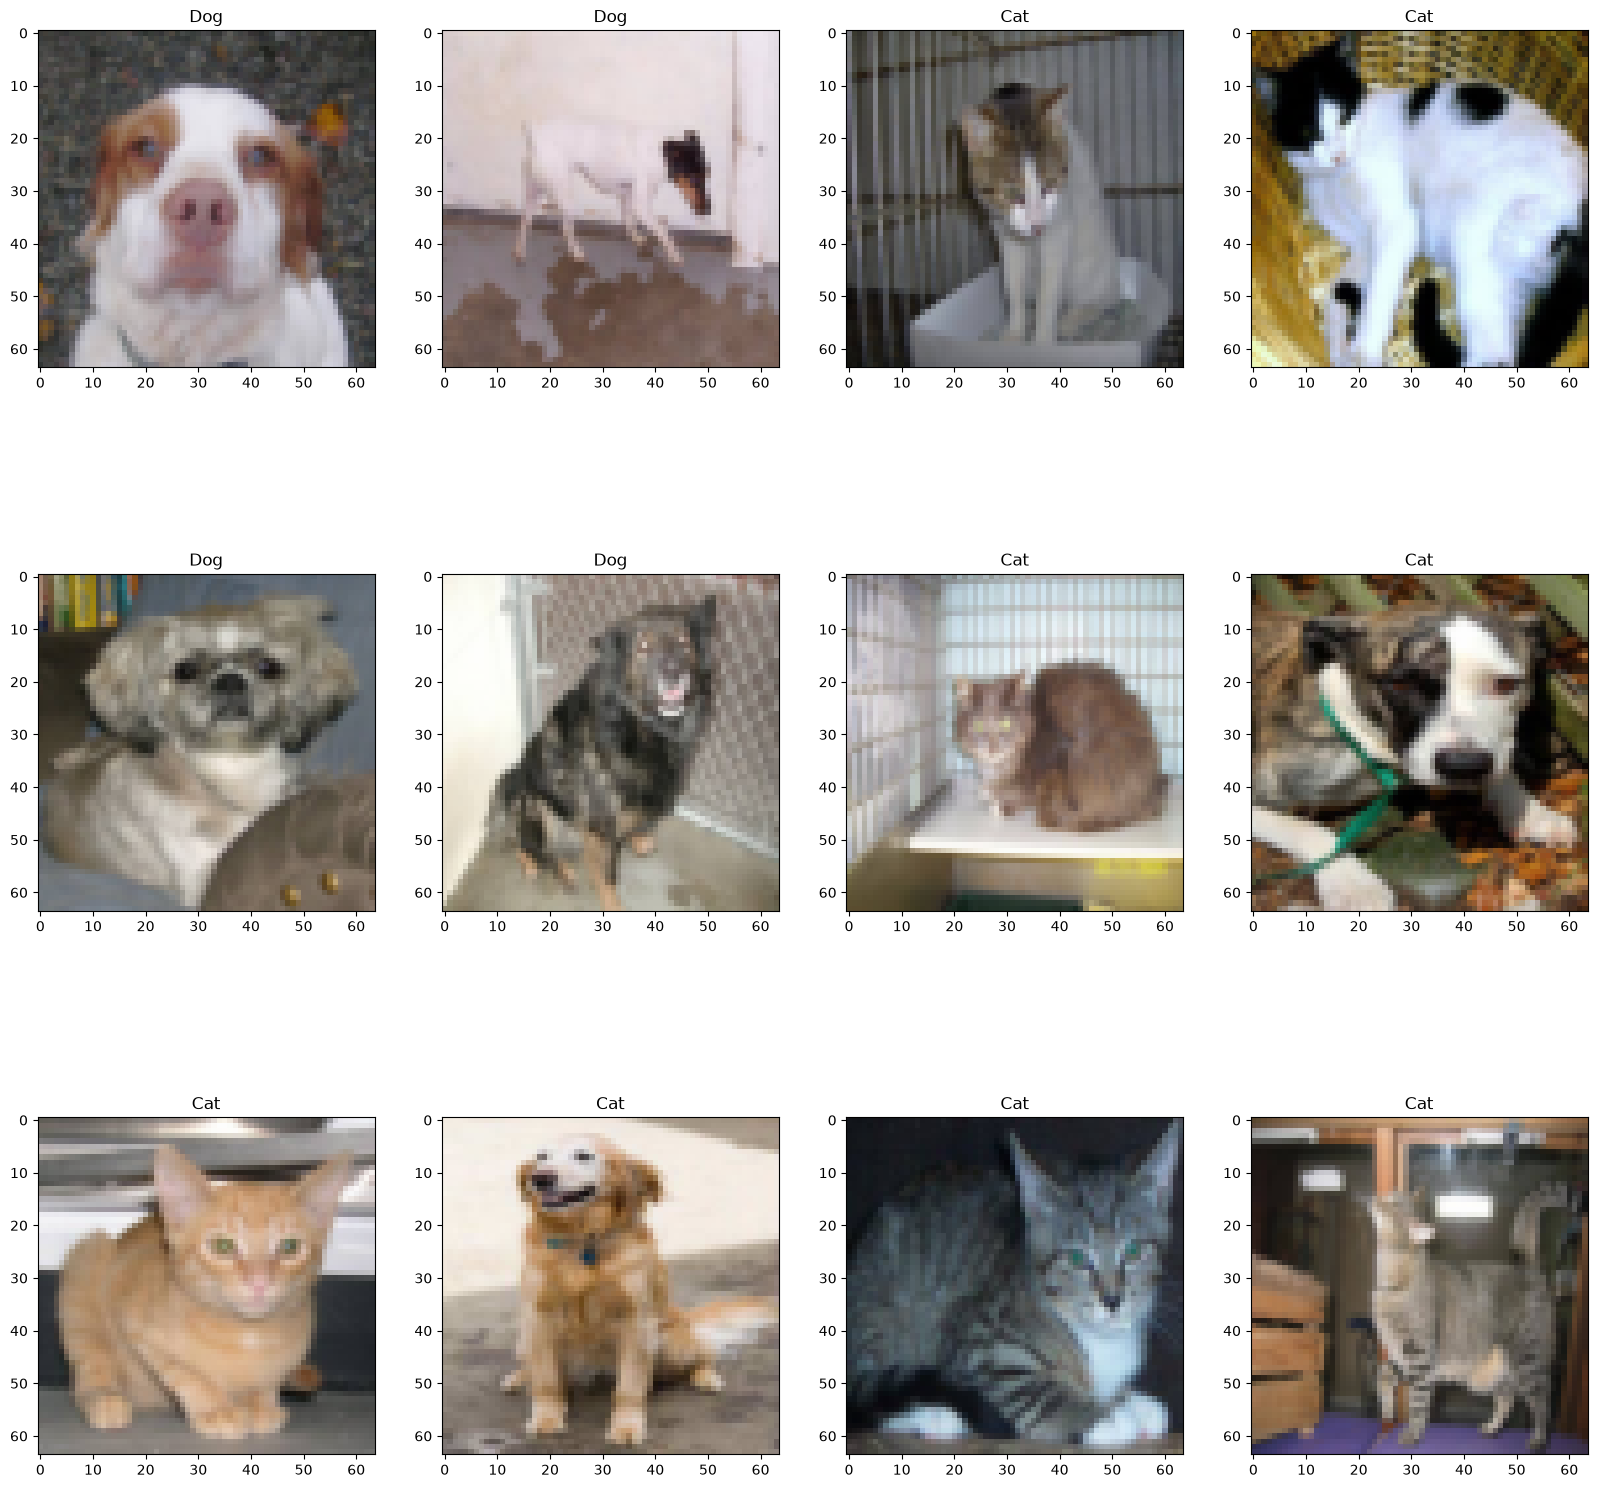

In [46]:
# Plot X_test along with label from our prediction

plt.figure(figsize = (20,20))
for i in range(12):
    plt.subplot(3,4,i+1)
    plt.imshow(X_test[i])
    if pred[i] == 1:
        plt.title('Cat')
    else:
        plt.title('Dog')

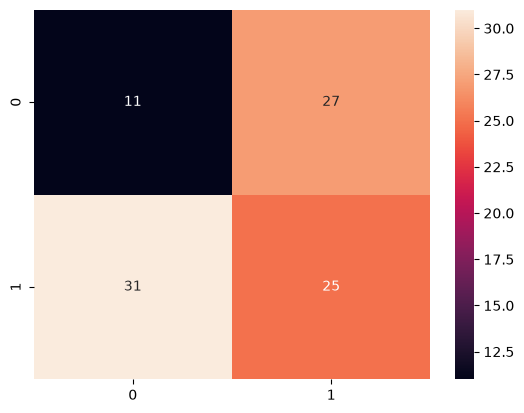

In [47]:
# Plot confusion matrix on a heatmap

sns.heatmap(confusion_matrix(y_test,pred), annot = True)
plt.show()

# RECURRENT NEURAL NETWORK (RNN)

## Project - Emotions in Text Prediction with LSTM (Classification)

In [1]:
# Import Necessary Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
# Read the dataset

df = pd.read_csv('Downloads/Emotion_final.csv')

In [3]:
df.head()

,Text,Emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [4]:
# Print some of the texts along with its emotions

for i in range(10):
    print(df['Text'][i],'-', df['Emotion'][i])
    print()

i didnt feel humiliated - sadness

i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake - sadness

im grabbing a minute to post i feel greedy wrong - anger

i am ever feeling nostalgic about the fireplace i will know that it is still on the property - love

i am feeling grouchy - anger

ive been feeling a little burdened lately wasnt sure why that was - sadness

ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny - surprise

i feel as confused about life as a teenager or as jaded as a year old man - fear

i have been with petronas for years i feel that petronas has performed well and made a huge profit - happy

i feel romantic too - love



In [5]:
# View info

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21459 entries, 0 to 21458
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Text     21459 non-null  object
 1   Emotion  21459 non-null  object
dtypes: object(2)
memory usage: 335.4+ KB


In [6]:
# View basic statistical information about the dataset

df.describe()

,Text,Emotion
count,21459,21459
unique,21405,6
top,i feel so tortured by it,happy
freq,2,7029


In [7]:
# Check for null values

df.isna().sum()

Text       0
Emotion    0
dtype: int64

In [11]:
# Check for duplicated values

print(df.duplicated().sum())

0


In [9]:
df.drop_duplicates(inplace= True, keep = 'first')

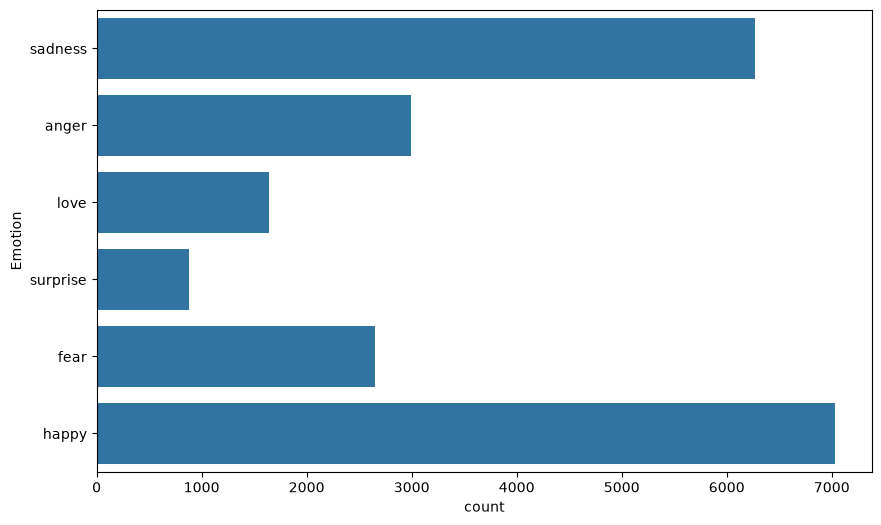

In [10]:
# Plot a countplot of 'Emotions'

plt.figure(figsize = (10,6))
sns.countplot(y = df['Emotion'])
plt.show()

In [12]:
# Create a function to preprocess the text

import re # regular expression
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer 

In [13]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\varsh\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [14]:
stopwords.words('english')

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [15]:
def preprocess(sentence):
    #removes all the special characters and split the sentence at spaces
    text = re.sub(r"[^a-zA-Z0-9]"," ",sentence).split()
    
    # converts words to lowercase and removes any stopwords 
    words = [x.lower() for x in text if x not in stopwords.words('english')]
    
    # Lemmatize the words
    lemma = WordNetLemmatizer() 
    word = [lemma.lemmatize(word,'v') for word in words ]
    
    # convert the list of words back into a sentence
    word = ' '.join(word)
    return word

In [17]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\varsh\AppData\Roaming\nltk_data...


True

In [18]:
# Apply the function on Text column

df['Text'] = df['Text'].apply(preprocess)

In [19]:
# Print some of the texts after the preprocess

for i in range(10):
    print(df['Text'][i])
    print()

didnt feel humiliate

go feel hopeless damn hopeful around someone care awake

im grab minute post feel greedy wrong

ever feel nostalgic fireplace know still property

feel grouchy

ive feel little burden lately wasnt sure

ive take milligrams time recommend amount ive fall asleep lot faster also feel like funny

feel confuse life teenager jade year old man

petronas years feel petronas perform well make huge profit

feel romantic



In [20]:
# Split the dataset into Input and Target Variables

X = df['Text']
y = df['Emotion']

In [21]:
# One Hot encode the Target variables

from sklearn.preprocessing import LabelBinarizer

In [22]:
encoder = LabelBinarizer()
y = encoder.fit_transform(y)

In [23]:
# Check encoder classes

labels = encoder.classes_
labels

array(['anger', 'fear', 'happy', 'love', 'sadness', 'surprise'],
      dtype='<U8')

In [24]:
# Split the dataset into Training and Testing Set

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.20)

In [29]:
# Convert text to Sequence and add padding

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [30]:
tokenizer = Tokenizer(num_words=5000)

In [31]:
# "fit_on_texts" - This method creates the vocabulary index based on word frequency. Each word gets a unique id

In [32]:
tokenizer.fit_on_texts(X_train)

In [33]:
vocab_size = len(tokenizer.word_index) + 1

In [34]:
tokenizer

In [35]:
def text_encoding(txt):
    # texts_to_sequences Transforms each text in texts to a sequence of integers.
    encoded_docs = tokenizer.texts_to_sequences(txt)
    
    # pad_sequences is used to ensure that all sequences in a list have the same length.
    padded_sequence = pad_sequences(encoded_docs, maxlen=128)    
       
    return padded_sequence

In [36]:
# Apply the function on both Training and Testing set

X_train = text_encoding(X_train)
X_test = text_encoding(X_test)

In [37]:
# Create a keras Sequential model with LSTM Layers

vocab_size

13830

In [38]:
from keras import Sequential
from keras import layers

In [42]:
model = Sequential()
### Embedding layer
model.add(layers.Input(shape=(128,)))
model.add(layers.Embedding(vocab_size, 128))

### Lstm layer
### return_sequences: Whether to return the last output in the output sequence, or the full sequence.
model.add(layers.LSTM(128,  return_sequences=True))
model.add(layers.Dropout(0.2))
model.add(layers.LSTM(128))
model.add(layers.Dense(64, activation = 'relu'))
model.add(layers.Dropout(0.2))

model.add(layers.Dense(6, activation='softmax'))

In [43]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ (None, 128, 128)            │       1,770,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 128, 128)            │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 6)                   │             390 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,042,054 (7.79 MB)

 Trainable params: 2,042,054 (7.79 MB)

 Non-trainable params: 0 (0.00 B)

In [44]:
# Compile the model

model.compile(loss = 'categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [45]:
# Train the model

model.fit(X_train, y_train, epochs=10, validation_split = 0.2)

Epoch 1/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 170s 374ms/step - accuracy: 0.5425 - loss: 1.1496 - val_accuracy: 0.8290 - val_loss: 0.4876
Epoch 2/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 147s 341ms/step - accuracy: 0.8934 - loss: 0.3086 - val_accuracy: 0.8913 - val_loss: 0.3514
Epoch 3/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 160s 373ms/step - accuracy: 0.9357 - loss: 0.1788 - val_accuracy: 0.8928 - val_loss: 0.3157
Epoch 4/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 139s 227ms/step - accuracy: 0.9535 - loss: 0.1264 - val_accuracy: 0.8884 - val_loss: 0.3190
Epoch 5/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 70s 162ms/step - accuracy: 0.9647 - loss: 0.0949 - val_accuracy: 0.8946 - val_loss: 0.3370
Epoch 6/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 77s 179ms/step - accuracy: 0.9706 - loss: 0.0809 - val_accuracy: 0.8978 - val_loss: 0.3549
Epoch 7/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 70s 164ms/step - accuracy: 0.9765 - loss: 0.0612 - val_accuracy: 0.8911 - val_loss: 0.3868
Epoch 8/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 75s 175ms/step - accuracy: 0.9805 - los

In [46]:
# Make Prediction with X_test

y_pred = model.predict(X_test)

135/135 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step


In [47]:
y_pred = [np.argmax(i) for i in y_pred]

In [48]:
len(y_pred)

4292

In [49]:
len(y_test)

4292

In [50]:
y_test = [np.argmax(i) for i in y_test]

In [51]:
# Model Evaluation

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [52]:
# Accuracy score

accuracy_score(y_test, y_pred)

0.9012115563839702

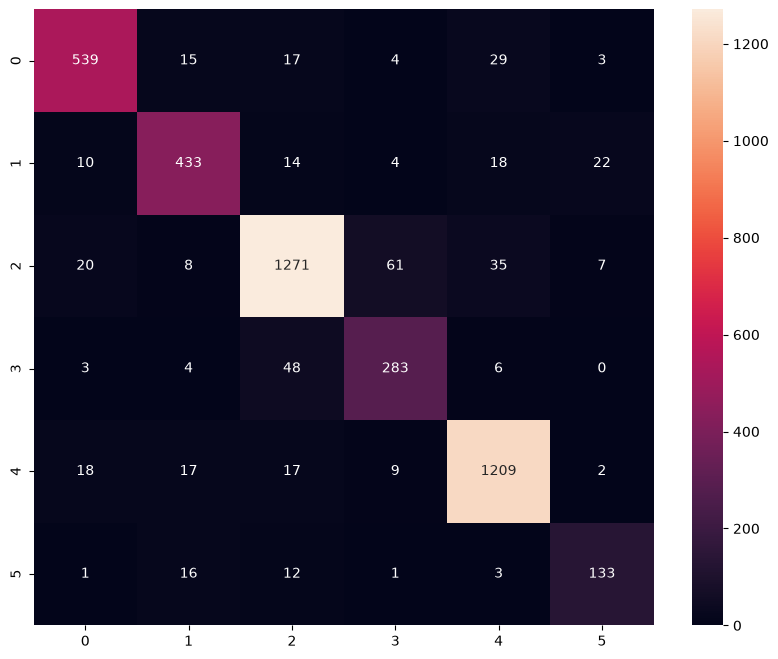

In [53]:
# Confusion Matrix

plt.figure(figsize = (10,8))
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, fmt = 'd')
plt.show()

In [61]:
# Classification report

print(classification_report(y_test, y_pred,target_names=[str(val) for val in labels.values()]))

              precision    recall  f1-score   support

       anger       0.91      0.89      0.90       607
        fear       0.88      0.86      0.87       501
       happy       0.92      0.91      0.91      1402
        love       0.78      0.82      0.80       344
     sadness       0.93      0.95      0.94      1272
    surprise       0.80      0.80      0.80       166

    accuracy                           0.90      4292
   macro avg       0.87      0.87      0.87      4292
weighted avg       0.90      0.90      0.90      4292



In [62]:
labels = dict(enumerate(encoder.classes_))

In [63]:
labels = {key: str(val) for key, val in labels.items()}

In [64]:
labels

{0: 'anger', 1: 'fear', 2: 'happy', 3: 'love', 4: 'sadness', 5: 'surprise'}

In [65]:
test = text_encoding(['This is a test sentence'])

In [66]:
result = model.predict([test])

C:\Users\varsh\anaconda3\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=('Tensor(shape=(1, 128))',)
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step


In [68]:
result = np.argmax(model.predict)

In [69]:
labels[np.argmax(model.predict([test]))]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step


'fear'

In [70]:
# Create a function that inputs text and outputs the prediction

def prediction(text):
    sequence = text_encoding([text])
    pred = model.predict([sequence])
    pred = np.argmax(pred)
    pred = labels[pred]
    return pred

In [71]:
prediction('I am a very happy person')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


'happy'

## Project - Implementing LSTM neural network with TensorFlow Keras (Regression)

In [72]:
# Here, we will use the stock price dataset to build an LSTM in keras that will predict if the stock will go up or down.

In [73]:
# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [74]:
# Read 'tatatrain.csv'

train = pd.read_csv('Downloads/tatatrain.csv')

In [75]:
# View head

train.head()

,Date,Open,High,Low,Last,Close,Total Trade Quantity,Turnover (Lacs)
0,2018-09-28,234.05,235.95,230.20,233.50,233.75,3069914,7162.35
1,2018-09-27,234.55,236.80,231.10,233.80,233.25,5082859,11859.95
2,2018-09-26,240.00,240.00,232.50,235.00,234.25,2240909,5248.60
3,2018-09-25,233.30,236.75,232.00,236.25,236.10,2349368,5503.90
4,2018-09-24,233.55,239.20,230.75,234.00,233.30,3423509,7999.55


In [76]:
# Check the shape of the dataset

train.shape

(2035, 8)

In [77]:
# We only need 'Open' feature in our dataset, Remove the rest
# Open column represent the starting price of the stock for the day

train_data = train[['Open']]

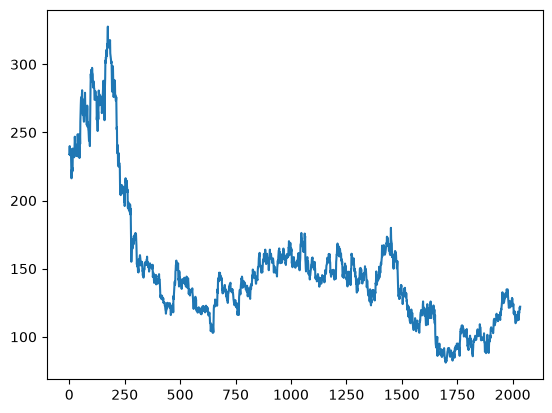

In [78]:
# Plot Open price 

plt.plot(train_data)

In [79]:
# Scale the data with MinMaxScaler
# To produce the best-optimized results with the models, we are required to scale the data, For this task, we are leveraging scikit-learn library's minmax scaler for converting the input values betweeen 0 to 1.

from sklearn.preprocessing import MinMaxScaler

In [80]:
scaler = MinMaxScaler()

In [81]:
train_data = scaler.fit_transform(train_data)

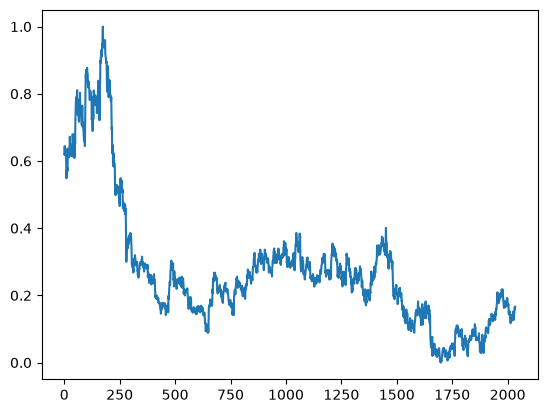

In [82]:
# Plot the open prices after scaling

plt.plot(train_data)

In [83]:
# Creating data with Timesteps
# When we are working with LSTM's, we need to keep the data in a specific format. Once the data is created in the form of 60 timesteps, we can then convert it into a Numpy array. Finally, the data is converted to a 3 dimensional array, 60 timeframes, and also one feature at each step.

len(train_data)

2035

In [84]:
X = []
y = []

for i in range(60, 2035):
    X.append(train_data[i-60:i,0])
    y.append(train_data[i,0])
    
X = np.array(X)
y = np.array(y)

In [85]:
X = X.reshape((X.shape[0], X.shape[1],1))

In [86]:
#  Split the dataset into training and testing set

X_train = X[0:1700]
X_test = X[1700:]

y_train = y[0:1700]
y_test = y[1700:]

In [87]:
# Check the shape of X_train

X_train.shape

(1700, 60, 1)

In [88]:
# Import Sequential and layers from Keras

from tensorflow.keras import Sequential, layers

In [89]:
# Building an LSTM model with Keras

model = Sequential()

model.add(layers.LSTM(50, return_sequences = True, input_shape = (X_train.shape[1],1)))
model.add(layers.Dropout(0.2))

model.add(layers.LSTM(50, return_sequences = True))
model.add(layers.Dropout(0.2))

model.add(layers.LSTM(50))
model.add(layers.Dropout(0.2))

model.add(layers.Dense(1))

C:\Users\varsh\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [90]:
# Check the summary of our model

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                        │ (None, 60, 50)              │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 60, 50)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 60, 50)              │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 60, 50)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_6 (LSTM)                        │ (None, 50)                  │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 50,851 (198.64 KB)

 Trainable params: 50,851 (198.64 KB)

 Non-trainable params: 0 (0.00 B)

In [91]:
# Compile the model
# We compile the model with the help of adam optimizer. The error is computed using mean_squared_error.

model.compile(optimizer = 'adam', loss = 'mean_squared_error')

In [92]:
# Train the model
# Finally, the model is fit using 100 epochs with a batch size of 32.

model.fit(X_train, y_train, epochs = 100, batch_size = 32)

Epoch 1/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - loss: 0.0110
Epoch 2/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 0.0029
Epoch 3/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0027
Epoch 4/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0026
Epoch 5/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 0.0025
Epoch 6/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0024
Epoch 7/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - loss: 0.0024
Epoch 8/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - loss: 0.0022
Epoch 9/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - loss: 0.0022
Epoch 10/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - loss: 0.0020
Epoch 11/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - loss: 0.0021
Epoch 12/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - loss: 0.0020
Epoch 13/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - loss: 0.0018
Epoch 14/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 0.0016
Epoch 15/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - lo

In [93]:
# Predicting future stock using the Test Set

predicted_stock_price = model.predict(X_test)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step


In [94]:
predicted_stock_price = scaler.inverse_transform(predicted_stock_price)

In [95]:
predicted_stock_price.shape

(275, 1)

In [96]:
y_test = y_test.reshape(275,1)

In [97]:
y_test = scaler.inverse_transform(y_test)

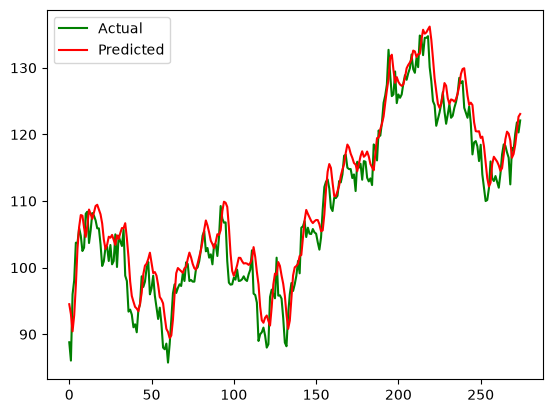

In [98]:
# Plotting the results

plt.plot(y_test, color = 'green', label = 'Actual')
plt.plot(predicted_stock_price, color = 'red', label = 'Predicted')
plt.legend()

# GATED RECURRENT UNIT (GRU)

## Project - AG News Classification 

In [5]:
# Import Necessary Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.preprocessing import LabelBinarizer
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [6]:
# Read the dataset

df = pd.read_csv('Downloads/agnews.csv')

In [7]:
# Save only a portion of the dataset

df = df[0:20000]

In [8]:
df.head()

,Class Index,Title,Description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


In [9]:
# Shuffle the dataset

df = df.sample(frac = 1)

In [10]:
df.reset_index(drop = True, inplace = True)

In [11]:
for i in range(10):
    print(df['Description'][i],'-', df['Class Index'][i])
    print()

AP - India is rethinking its plan to send a man to the moon by 2015, as the mission would cost a lot of money and yield very little in return, the national space agency said Thursday. - 4

PC World - Alternative browser will be available on portable devices running Microsoft's OS. - 4

Chandra X-Ray Observatory -- A spectacular new image of Cassiopeia A from NASA's Chandra X-ray Observatory released today has nearly 200 times more data than the "First Light" Chandra image of this object made five years ago. The new image reveals clues that the initial explosion caused by the collapse of a massive star was far more complicated than suspected... - 4

The world number one broke a jittery Mauresmo twice to take the opening set and the Frenchwoman failed to get a foot-hold in the second set. - 2

AFP - Police and officials in Gujarat are slowly starting to reveal how Hindu nationalists ruling the western Indian state either turned a blind eye or deliberately inflamed deadly Hindu-Muslim rio

In [12]:
# Check Info

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Class Index  20000 non-null  int64 
 1   Title        20000 non-null  object
 2   Description  20000 non-null  object
dtypes: int64(1), object(2)
memory usage: 468.9+ KB


In [13]:
# View basic statistical information about the dataset

df.describe(include = 'all')

,Class Index,Title,Description
count,20000.000000,20000,20000
unique,NaN,19020,19781
top,NaN,SI.com,Evidence from busy rovers suggests one-time pr...
freq,NaN,13,4
mean,2.484500,NaN,NaN
std,1.133633,NaN,NaN
min,1.000000,NaN,NaN
25%,1.000000,NaN,NaN
50%,2.000000,NaN,NaN
75%,4.000000,NaN,NaN


In [14]:
# Check for missing values

df.isna().sum()

Class Index    0
Title          0
Description    0
dtype: int64

In [16]:
# Check for duplicates

print(df.duplicated().sum())

0


C:\Users\varsh\AppData\Local\Temp\ipykernel_15584\1502976296.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y = df['Class Index'],palette='husl')


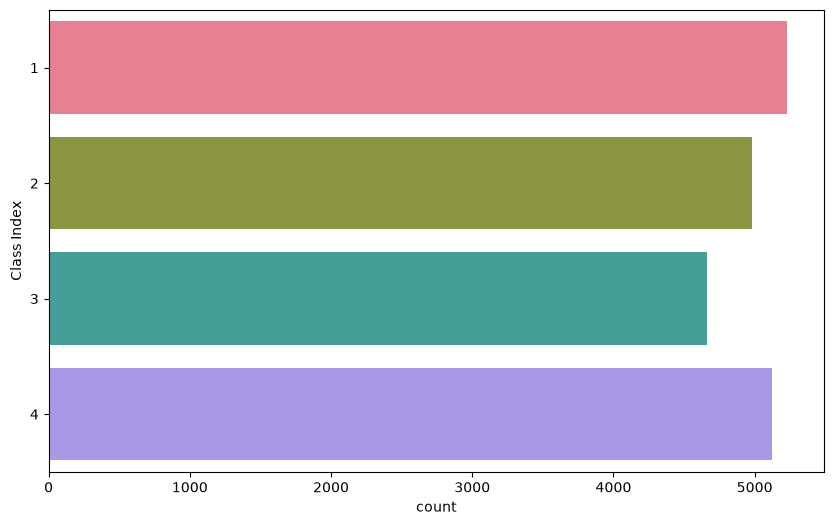

In [19]:
# Plot a countplot of the Class Index

plt.figure(figsize = (10,6))
sns.countplot(y = df['Class Index'],palette='husl')
plt.show()

In [20]:
# Create a funciton to preprocess the text

def preprocess(sentence):
    #removes all the special characters and split the sentence at spaces
    text = re.sub(r"[^a-zA-Z0-9]"," ",sentence).split()
    
    # converts words to lowercase and removes any stopwords
    words = [x.lower() for x in text if x not in stopwords.words('english')]
    
    # Lemmatize the words
    lemma = WordNetLemmatizer()
    word = [lemma.lemmatize(word,'v') for word in words ]
    
    # convert the list of words back into a sentence
    word = ' '.join(word)
    return word

In [21]:
# Apply the preprocess function to the description

df['Description'] = df['Description'].apply(preprocess)

In [22]:
for i in range(10):
    print(df['Description'][i],'-', df['Class Index'][i])
    print()

ap india rethink plan send man moon 2015 mission would cost lot money yield little return national space agency say thursday - 4

pc world alternative browser available portable devices run microsoft os - 4

chandra x ray observatory a spectacular new image cassiopeia a nasa chandra x ray observatory release today nearly 200 time data first light chandra image object make five years ago the new image reveal clue initial explosion cause collapse massive star far complicate suspect - 4

the world number one break jittery mauresmo twice take open set frenchwoman fail get foot hold second set - 2

afp police officials gujarat slowly start reveal hindu nationalists rule western indian state either turn blind eye deliberately inflame deadly hindu muslim riot 2002 - 1

andy flintoff one rare sportsmen enhance stature simply play india captain saurav ganguly try put finger lord 39 explain quot england far different side without - 2

a fresh diplomatic crisis loom us officials indicate would ob

In [23]:
# Split Input & Target Variables

X = df['Description']
y = df['Class Index']

In [24]:
# One Hot encode our Target Variable

encoder = LabelBinarizer()
y = encoder.fit_transform(y)

In [25]:
labels = encoder.classes_
labels

array([1, 2, 3, 4])

In [26]:
# Split the dataset into Training & Testing Set

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.20)

In [27]:
# Create a keras Tokenizer object
# In the Keras library, the Tokenizer is a class that can be used to preprocess text data. It allows you to convert a collection of text documents into a numerical representation that can be used as input to a machine learning model.

tokenizer = Tokenizer(num_words=5000)

In [28]:
# fit on text for our X

tokenizer.fit_on_texts(X)

In [29]:
vocab_size = len(tokenizer.word_index) + 1

In [30]:
# Create a function to convert text to numerical representation and add padding

def text_encoding(txt):
    # texts_to_sequences Transforms each text in texts to a sequence of integers.
    encoded_docs = tokenizer.texts_to_sequences(txt)
    
    # pad_sequences is used to ensure that all sequences in a list have the same length.
    padded_sequence = pad_sequences(encoded_docs, maxlen=128)    
       
    return padded_sequence

In [31]:
# Apply the function to our X_train & X_test

X_train = text_encoding(X_train)
X_test = text_encoding(X_test)

In [34]:
# Create keras Sequential model with GRU Layers

model = Sequential()
### Embedding layer
model.add(layers.Input(shape=(128,)))
model.add(layers.Embedding(vocab_size, 128))

### GRU layer
### return_sequences: Whether to return the last output in the output sequence, or the full sequence.
model.add(layers.GRU(128,  return_sequences=True))
model.add(layers.Dropout(0.2))
model.add(layers.GRU(128))
model.add(layers.Dense(64, activation = 'relu'))
model.add(layers.Dropout(0.2))

model.add(layers.Dense(4, activation='softmax'))

In [35]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ (None, 128, 128)            │       2,989,440 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_2 (GRU)                          │ (None, 128, 128)            │          99,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_3 (GRU)                          │ (None, 128)                 │          99,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 4)                   │             260 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,196,100 (12.19 MB)

 Trainable params: 3,196,100 (12.19 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# Compile the model

model.compile(loss = 'categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [37]:
# Train the model with our Training Set

model.fit(X_train, y_train, epochs=10, validation_split = 0.2)

Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 66s 159ms/step - accuracy: 0.7542 - loss: 0.6530 - val_accuracy: 0.8497 - val_loss: 0.4452
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 63s 159ms/step - accuracy: 0.8921 - loss: 0.3265 - val_accuracy: 0.8628 - val_loss: 0.4149
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 62s 155ms/step - accuracy: 0.9249 - loss: 0.2300 - val_accuracy: 0.8469 - val_loss: 0.4771
Epoch 4/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 64s 160ms/step - accuracy: 0.9471 - loss: 0.1659 - val_accuracy: 0.8494 - val_loss: 0.5237
Epoch 5/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 66s 165ms/step - accuracy: 0.9592 - loss: 0.1233 - val_accuracy: 0.8347 - val_loss: 0.6187
Epoch 6/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 59s 147ms/step - accuracy: 0.9714 - loss: 0.0870 - val_accuracy: 0.8444 - val_loss: 0.6305
Epoch 7/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 64s 159ms/step - accuracy: 0.9770 - loss: 0.0727 - val_accuracy: 0.8381 - val_loss: 0.7808
Epoch 8/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 59s 146ms/step - accuracy: 0.9798 - loss: 0

In [38]:
# Make predictions with Test set

y_pred = model.predict(X_test)

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step


In [39]:
y_pred = [np.argmax(i) for i in y_pred]

In [40]:
y_test = [np.argmax(i) for i in y_test]

In [41]:
# Check accuracy score

accuracy_score(y_test, y_pred)

0.83975

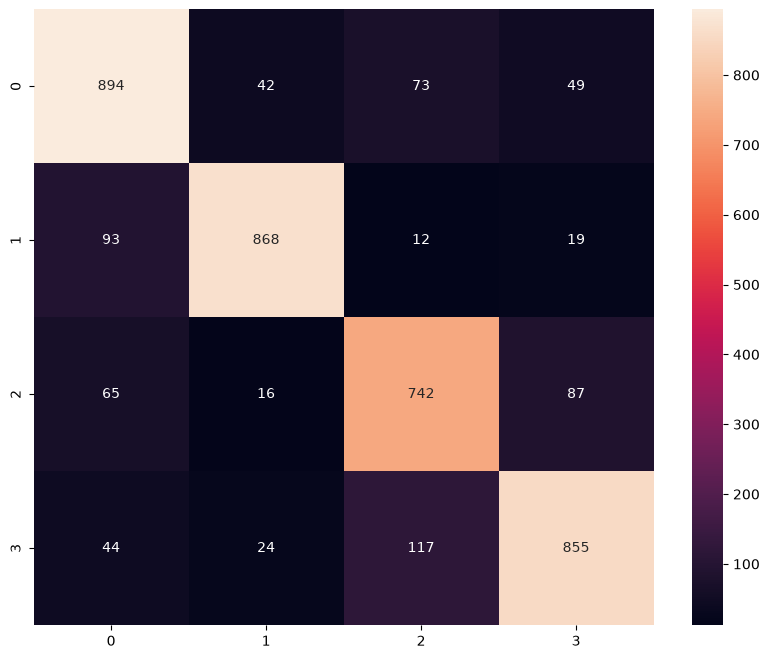

In [42]:
# Confusion matrix

plt.figure(figsize = (10,8))
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, fmt = 'd')
plt.show()

In [43]:
# Classification Report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.84      0.83      1058
           1       0.91      0.88      0.89       992
           2       0.79      0.82      0.80       910
           3       0.85      0.82      0.83      1040

    accuracy                           0.84      4000
   macro avg       0.84      0.84      0.84      4000
weighted avg       0.84      0.84      0.84      4000



In [44]:
labels = dict(enumerate(encoder.classes_))

In [45]:
labels = {key: str(val) for key, val in labels.items()}

In [46]:
labels

{0: '1', 1: '2', 2: '3', 3: '4'}

In [47]:
test = text_encoding(['This is a test sentence'])

In [48]:
result = model.predict([test])

C:\Users\varsh\anaconda3\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=('Tensor(shape=(1, 128))',)
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step


In [49]:
result = np.argmax(model.predict)

In [50]:
labels[np.argmax(model.predict([test]))]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


'1'

In [51]:
# Create a function that inputs text and outputs the prediction

def prediction(text):
    sequence = text_encoding([text])
    pred = model.predict([sequence])
    pred = np.argmax(pred)
    pred = labels[pred]
    return pred

In [53]:
prediction('The tennis player won her fifth Grand Slam title after defeating the world number one in straight sets.')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


'2'

# TRANSFER LEARNING

## Project - Flower Classification

In [2]:
!pip install tensorflow-hub

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------------------------ --------- 1.3/1.7 MB 11.1 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 10.5 MB/s  0:00:00

   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------

In [30]:
# Import Required Libraries and Modules

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle
from skimage.transform import resize
from glob import glob
from sklearn.model_selection import train_test_split
import tensorflow as tf
import tensorflow_hub as hub
from tensorflow.keras import Sequential, layers
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [13]:
# Collect Image Paths for Each Flower Category (daisy,dandelion,rose,sunflower,tulip)

daisy = glob('Downloads/archive (5)/flower_photos/daisy/*.jpg')
dandelion = glob('Downloads/archive (5)/flower_photos/dandelion/*.jpg')
rose = glob('Downloads/archive (5)/flower_photos/roses/*.jpg')
sunflower = glob('Downloads/archive (5)/flower_photos/sunflowers/*.jpg')
tulip = glob('Downloads/archive (5)/flower_photos/tulips/*.jpg')

In [14]:
# Define Classes and Corresponding Labels

classes = {0: 'daisy', 1: 'dandelion', 2: 'rose', 3: 'sunflower', 4: 'tulip'}

In [15]:
# Load and Label Images for Each Flower Category

images = []
labels = []

for i in daisy:
    img = plt.imread(i)
    images.append(img)
    labels.append(0)

for i in dandelion:
    img = plt.imread(i)
    images.append(img)
    labels.append(1)

for i in rose:
    img = plt.imread(i)
    images.append(img)
    labels.append(2)

for i in sunflower:
    img = plt.imread(i)
    images.append(img)
    labels.append(3)

for i in tulip:
    img = plt.imread(i)
    images.append(img)
    labels.append(4)

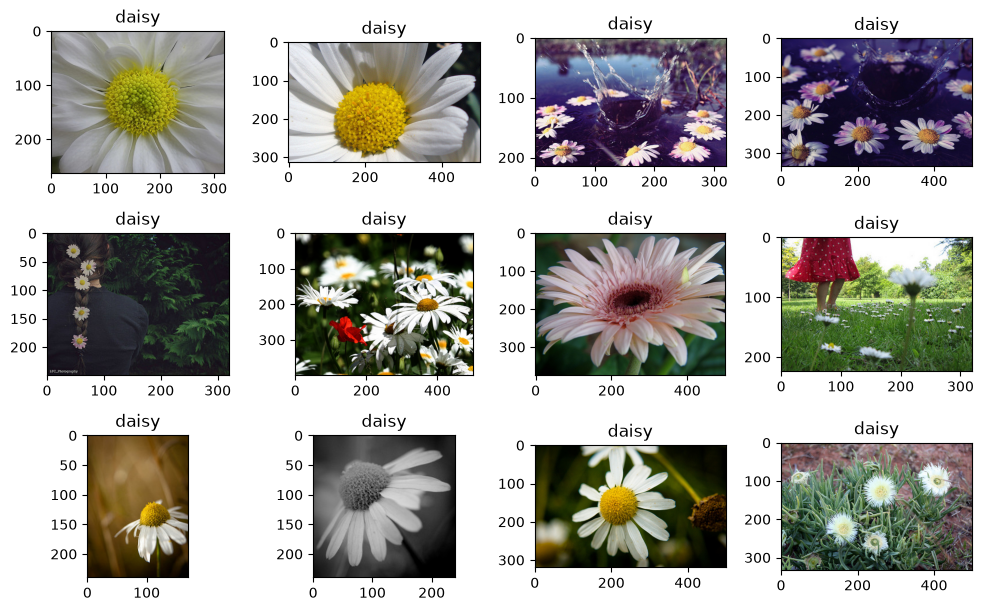

In [16]:
# Plot first few images

plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(4, 4, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(classes[labels[i]])
plt.tight_layout()

In [17]:
# Shuffle the images

images,labels = shuffle(images,labels)

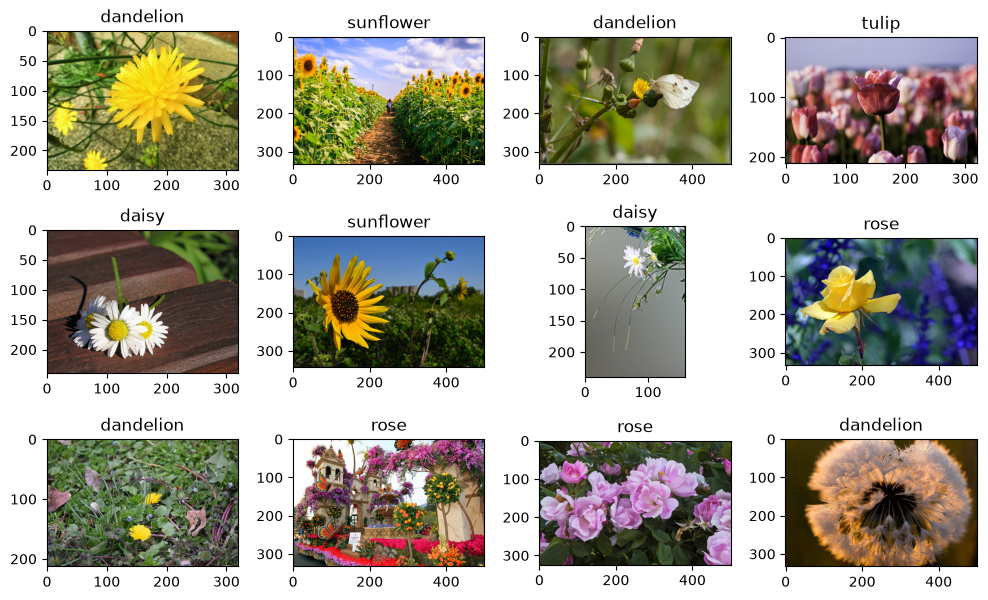

In [18]:
# Plot some of the image after the shuffle

plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(4, 4, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(classes[labels[i]])
plt.tight_layout()

In [19]:
# Resize Images to MobileNetV2 Input Shape (224,224,3)

X = []

for i in images:
    X.append(resize(i, (224,224,3)))

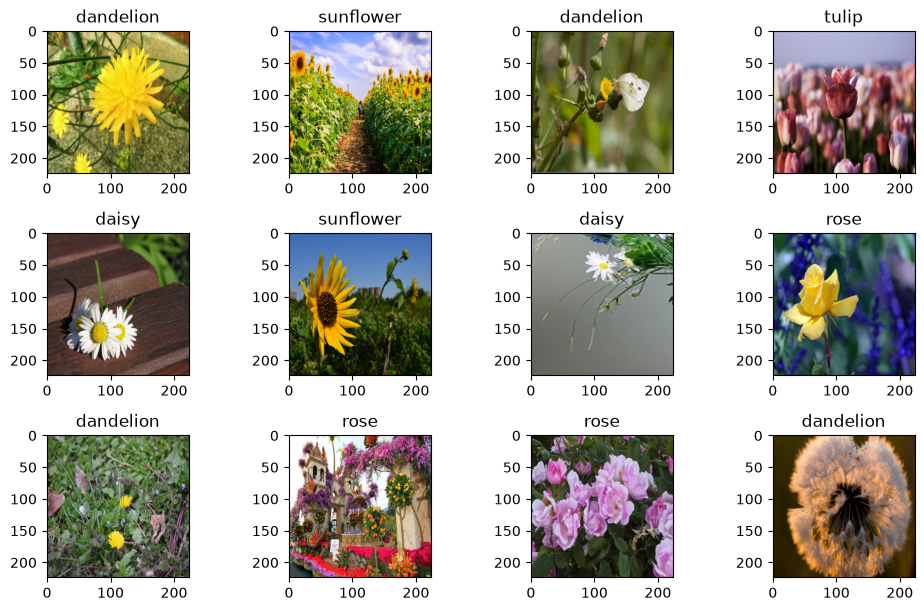

In [20]:
# Plot some of the images after resizing

plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(4, 4, i+1)
    plt.imshow(X[i], cmap='gray')
    plt.title(classes[labels[i]])
plt.tight_layout()

In [22]:
# Convert image and label datatypes from list to Numpy array

X = np.array(X, dtype=np.float32)
y = np.array(labels)

In [23]:
# Convert Images and Labels to NumPy Arrays

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

In [32]:
from tensorflow.keras.applications import MobileNetV2

pretrained_model_without_top_layer = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

pretrained_model_without_top_layer.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [33]:
# Define Number of Output Classes

num_of_classes = 5

In [34]:
model = tf.keras.Sequential([
    pretrained_model_without_top_layer,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.1),
    tf.keras.layers.Dense(14, activation='relu'),
    tf.keras.layers.Dense(num_of_classes, activation='softmax')
])

In [35]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │          81,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 14)                  │             910 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 5)                   │              75 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,340,953 (8.93 MB)

 Trainable params: 82,969 (324.10 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [36]:
# Compile Transfer Learning Model

model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

In [37]:
# Train the model

model.fit(X_train,y_train, epochs = 10, validation_split = 0.05)

Epoch 1/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 154s 2s/step - accuracy: 0.7522 - loss: 0.6731 - val_accuracy: 0.8503 - val_loss: 0.4093
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.8820 - loss: 0.3498 - val_accuracy: 0.8912 - val_loss: 0.3100
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 78s 892ms/step - accuracy: 0.9172 - loss: 0.2577 - val_accuracy: 0.8776 - val_loss: 0.3275
Epoch 4/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 79s 897ms/step - accuracy: 0.9398 - loss: 0.1927 - val_accuracy: 0.8707 - val_loss: 0.3218
Epoch 5/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 75s 855ms/step - accuracy: 0.9541 - loss: 0.1499 - val_accuracy: 0.8639 - val_loss: 0.3637
Epoch 6/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 94s 991ms/step - accuracy: 0.9631 - loss: 0.1156 - val_accuracy: 0.8912 - val_loss: 0.3020
Epoch 7/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 75s 854ms/step - accuracy: 0.9749 - loss: 0.0846 - val_accuracy: 0.8503 - val_loss: 0.3409
Epoch 8/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 76s 861ms/step - accuracy: 0.9792 - loss: 0.0721 - val_accuracy

In [38]:
# Model Prediction on Test Data

y_pred = model.predict(X_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 24s 972ms/step


In [39]:
y_pred = [np.argmax(i) for i in y_pred]

In [40]:
# Calculate Accuracy Score

accuracy_score(y_test,y_pred)

0.8841961852861036

<Axes: >

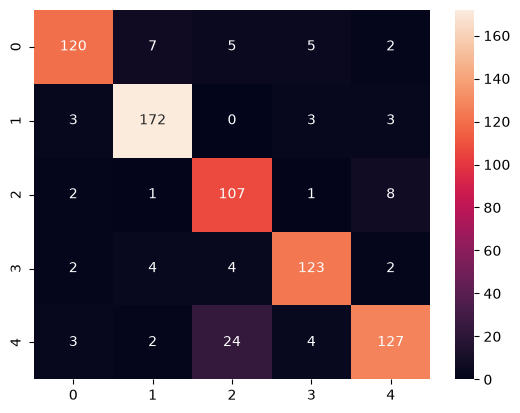

In [41]:
# Plot confusion matrix on heatmap

sns.heatmap(confusion_matrix(y_test,y_pred), annot = True, fmt = 'd')

In [42]:
# Print classification report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.86      0.89       139
           1       0.92      0.95      0.94       181
           2       0.76      0.90      0.83       119
           3       0.90      0.91      0.91       135
           4       0.89      0.79      0.84       160

    accuracy                           0.88       734
   macro avg       0.88      0.88      0.88       734
weighted avg       0.89      0.88      0.88       734



# AUTOENCODERS

In [1]:
# Import Libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

In [2]:
# Load MNIST Dataset

(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step


In [3]:
# Normalize the images

x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.

In [4]:
# Flatten the images (28x28 -> 784)

x_train = x_train.reshape((len(x_train), 784))
x_test = x_test.reshape((len(x_test), 784))

In [5]:
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

Training Data Shape: (60000, 784)
Testing Data Shape: (10000, 784)


In [6]:
# Encoder

input_layer = Input(shape=(784,))

encoded = Dense(128, activation='relu')(input_layer)
encoded = Dense(64, activation='relu')(encoded)
latent = Dense(16, activation='relu')(encoded)

In [7]:
# Decoder

decoded = Dense(64, activation='relu')(latent)
decoded = Dense(128, activation='relu')(decoded)
output_layer = Dense(784, activation='sigmoid')(decoded)

In [8]:
# Autoencoder Model

autoencoder = Model(input_layer, output_layer)

In [9]:
# Compile Model

autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

In [10]:
# Display Model Summary

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │           1,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 220,320 (860.62 KB)

 Trainable params: 220,320 (860.62 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Train Model

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    validation_data=(x_test, x_test)
)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - loss: 0.0694 - val_loss: 0.0437
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0368 - val_loss: 0.0319
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0298 - val_loss: 0.0275
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0266 - val_loss: 0.0249
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0242 - val_loss: 0.0230
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0227 - val_loss: 0.0218
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0218 - val_loss: 0.0211
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0212 - val_loss: 0.0206
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0206 - val_loss: 0.0203
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0202 - val_loss: 0.0197
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0198 - val_loss: 0.0193
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 

In [12]:
# Predict/Reconstruct Images

decoded_imgs = autoencoder.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [13]:
# Display Original and Reconstructed Images

n = 10

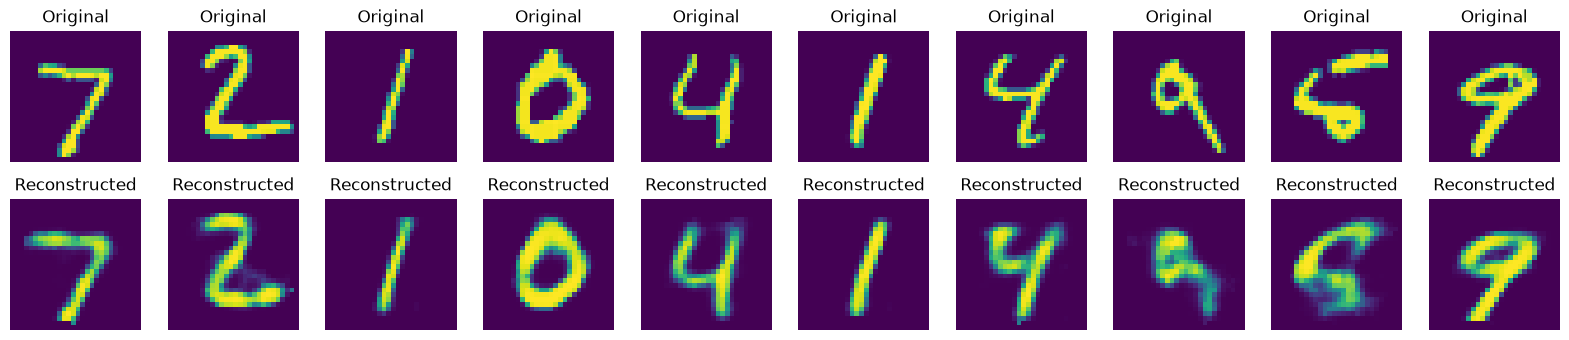

In [15]:
plt.figure(figsize=(20,4))

for i in range(n):

    # Original Image
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28,28))
    plt.title("Original")
    plt.axis('off')

    # Reconstructed Image
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28,28))
    plt.title("Reconstructed")
    plt.axis('off')

plt.show()

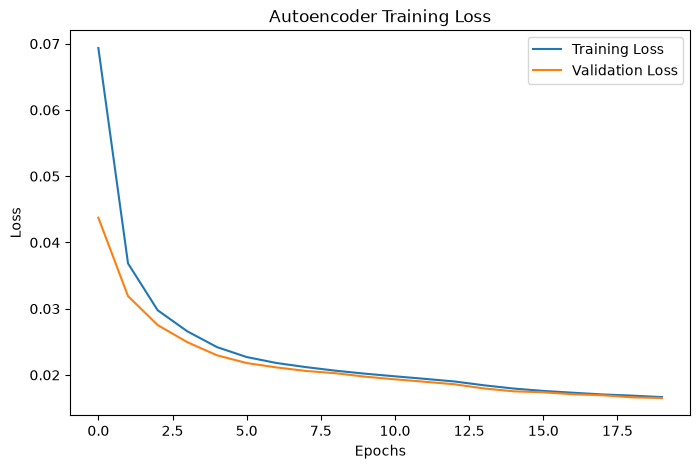

In [16]:
# Plot Training & Validation Loss

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()